<a href="https://colab.research.google.com/github/Johan16lindis/MachineLearning_NoSupervisado/blob/main/MachineLearning_NoSupervisado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning No Supervisado: Clustering y Reducción de Dimensionalidad

**Autor:** Yohan Steven Dussan Alzate

**Programa:** Ingeniería de Sistemas

**Institución:** Universidad de Cundinamarca

**Asignatura:** INTRODUCCION A MACHINE LEARNING

**Docente:** WILSON MAURO ROJAS REALES

**Fecha:** 25/10/2026

## Descripción del proyecto

Este proyecto tiene como objetivo implementar y analizar técnicas de aprendizaje automático no supervisado mediante Python y las librerías Scikit-learn, Pandas, NumPy y Matplotlib. Se desarrollarán los algoritmos K-means y clustering jerárquico, así como los métodos de reducción de dimensionalidad PCA y SVD. Los experimentos se realizarán en Google Colab utilizando el conjunto de datos Wine, con el propósito de explorar agrupaciones, representar datos en espacios de menor dimensión y comparar los resultados obtenidos.

In [1]:
#VAMOS A IMPORTAR DE LIBRERÍAS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

print("Librerías importadas correctamente.")


Librerías importadas correctamente.


In [2]:
#CARGA DEL CONJUNTO DE DATOS

datos = load_wine()

X = pd.DataFrame(
    datos.data,
    columns=datos.feature_names
)

# Etiquetas originales: se reservan para
# comparaciones descriptivas posteriores
y_referencia = datos.target

print("Dimensiones del conjunto de datos:", X.shape)

print("\nPrimeras cinco filas:")
display(X.head())

print("\nInformación de las variables:")
display(X.describe().round(2))

print("\nValores faltantes:", X.isnull().sum().sum())
print("Cantidad de variables:", X.shape[1])
print("Cantidad de registros:", X.shape[0])


Dimensiones del conjunto de datos: (178, 13)

Primeras cinco filas:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0



Información de las variables:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00



Valores faltantes: 0
Cantidad de variables: 13
Cantidad de registros: 178


In [3]:
#PREPROCESAMIENTO

escalador = StandardScaler()

X_escalado = escalador.fit_transform(X)

print("Dimensiones de los datos escalados:", X_escalado.shape)
print("Media aproximada de la primera variable:",
      round(X_escalado[:, 0].mean(), 4))
print("Desviación estándar aproximada:",
      round(X_escalado[:, 0].std(), 4))


Dimensiones de los datos escalados: (178, 13)
Media aproximada de la primera variable: 0.0
Desviación estándar aproximada: 1.0


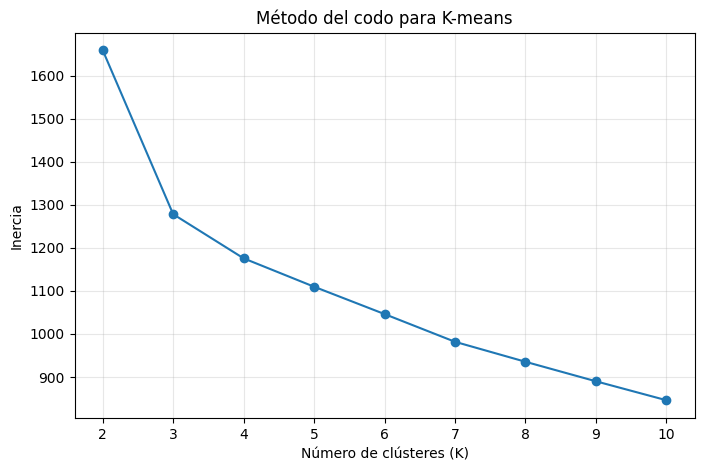

In [4]:
#K-MEANS: MÉTODO DEL CODO

inercias = []
valores_k = range(2, 11)

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    modelo.fit(X_escalado)
    inercias.append(modelo.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(valores_k), inercias, marker="o")
plt.title("Método del codo para K-means")
plt.xlabel("Número de clústeres (K)")
plt.ylabel("Inercia")
plt.xticks(list(valores_k))
plt.grid(True, alpha=0.3)
plt.show()


In [5]:
#ENTRENAMIENTO DE K-MEANS

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

etiquetas_kmeans = kmeans.fit_predict(X_escalado)

silueta_kmeans = silhouette_score(
    X_escalado,
    etiquetas_kmeans
)

print("Cantidad de clústeres:", len(np.unique(etiquetas_kmeans)))
print("Coeficiente de silueta:", round(silueta_kmeans, 4))

print("\nCantidad de registros por clúster:")
print(pd.Series(etiquetas_kmeans).value_counts().sort_index())


Cantidad de clústeres: 3
Coeficiente de silueta: 0.2849

Cantidad de registros por clúster:
0    65
1    51
2    62
Name: count, dtype: int64


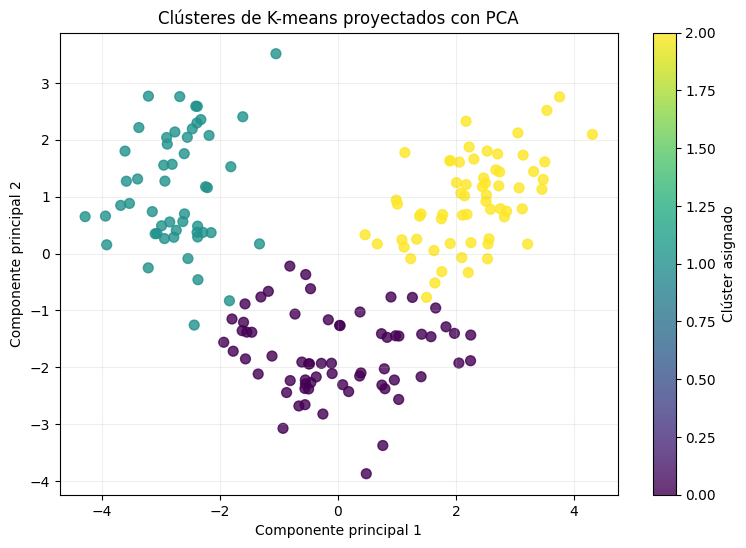

In [6]:
#VISUALIZACIÓN DE K-MEANS

pca_visual = PCA(n_components=2)
X_visual = pca_visual.fit_transform(X_escalado)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_visual[:, 0],
    X_visual[:, 1],
    c=etiquetas_kmeans,
    cmap="viridis",
    s=50,
    alpha=0.8
)

plt.title("Clústeres de K-means proyectados con PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.colorbar(label="Clúster asignado")
plt.grid(True, alpha=0.2)
plt.show()


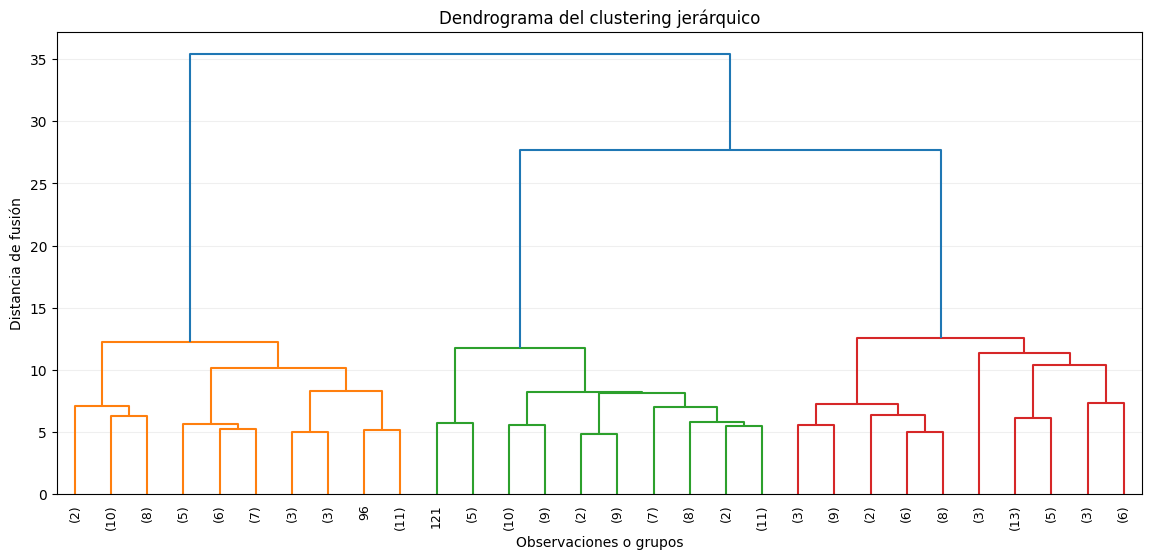

In [7]:
#CLUSTERING JERÁRQUICO

enlace = linkage(
    X_escalado,
    method="ward"
)

plt.figure(figsize=(14, 6))

dendrogram(
    enlace,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=9
)

plt.title("Dendrograma del clustering jerárquico")
plt.xlabel("Observaciones o grupos")
plt.ylabel("Distancia de fusión")
plt.grid(axis="y", alpha=0.2)
plt.show()


In [8]:
#MODELO JERÁRQUICO

jerarquico = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

etiquetas_jerarquicas = jerarquico.fit_predict(X_escalado)

silueta_jerarquica = silhouette_score(
    X_escalado,
    etiquetas_jerarquicas
)

print("Cantidad de clústeres:",
      len(np.unique(etiquetas_jerarquicas)))

print("Coeficiente de silueta:",
      round(silueta_jerarquica, 4))

print("\nCantidad de registros por clúster:")
print(
    pd.Series(etiquetas_jerarquicas)
    .value_counts()
    .sort_index()
)


Cantidad de clústeres: 3
Coeficiente de silueta: 0.2774

Cantidad de registros por clúster:
0    58
1    56
2    64
Name: count, dtype: int64


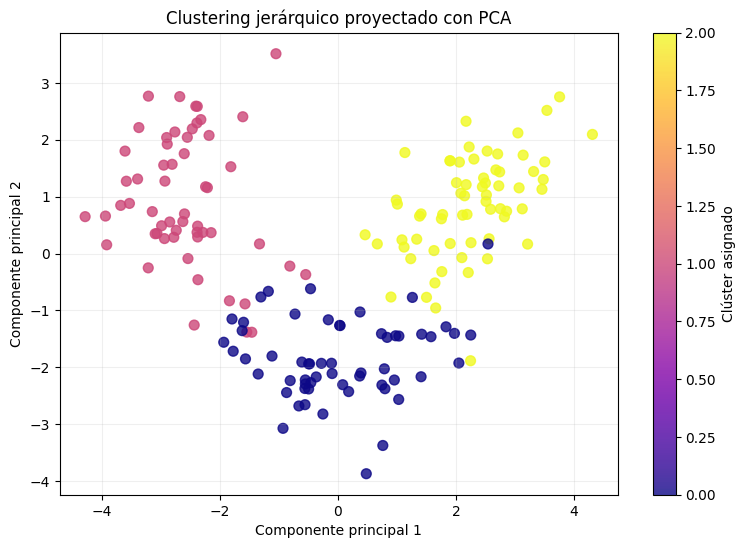

In [9]:
#VISUALIZACIÓN JERÁRQUICA

plt.figure(figsize=(9, 6))

plt.scatter(
    X_visual[:, 0],
    X_visual[:, 1],
    c=etiquetas_jerarquicas,
    cmap="plasma",
    s=50,
    alpha=0.8
)

plt.title("Clustering jerárquico proyectado con PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.colorbar(label="Clúster asignado")
plt.grid(True, alpha=0.2)
plt.show()


In [10]:
#PCA: REDUCCIÓN A DOS COMPONENTES


pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_escalado)

varianza_componentes = pca.explained_variance_ratio_
varianza_acumulada = varianza_componentes.sum()

print("Dimensiones originales:", X_escalado.shape)
print("Dimensiones reducidas:", X_pca.shape)

print(
    "Varianza explicada por componente:",
    np.round(varianza_componentes, 4)
)

print(
    "Varianza explicada acumulada:",
    round(varianza_acumulada, 4)
)


Dimensiones originales: (178, 13)
Dimensiones reducidas: (178, 2)
Varianza explicada por componente: [0.362  0.1921]
Varianza explicada acumulada: 0.5541


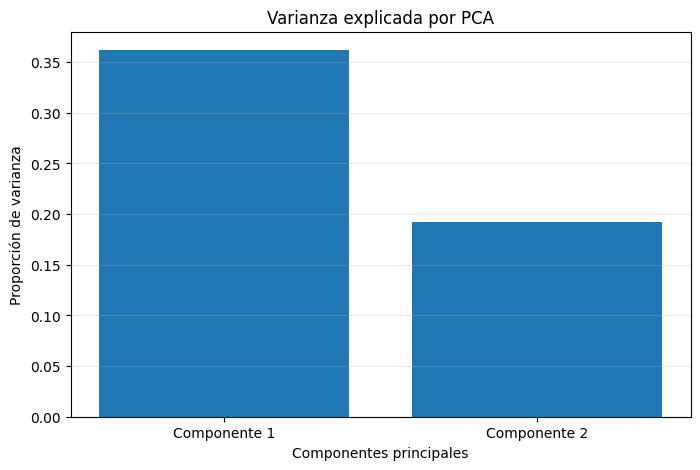

Varianza acumulada: 55.41%


In [11]:
#VARIANZA EXPLICADA POR PCA

plt.figure(figsize=(8, 5))

plt.bar(
    ["Componente 1", "Componente 2"],
    varianza_componentes
)

plt.title("Varianza explicada por PCA")
plt.ylabel("Proporción de varianza")
plt.xlabel("Componentes principales")
plt.grid(axis="y", alpha=0.3)
plt.show()

print(
    f"Varianza acumulada: {varianza_acumulada * 100:.2f}%"
)


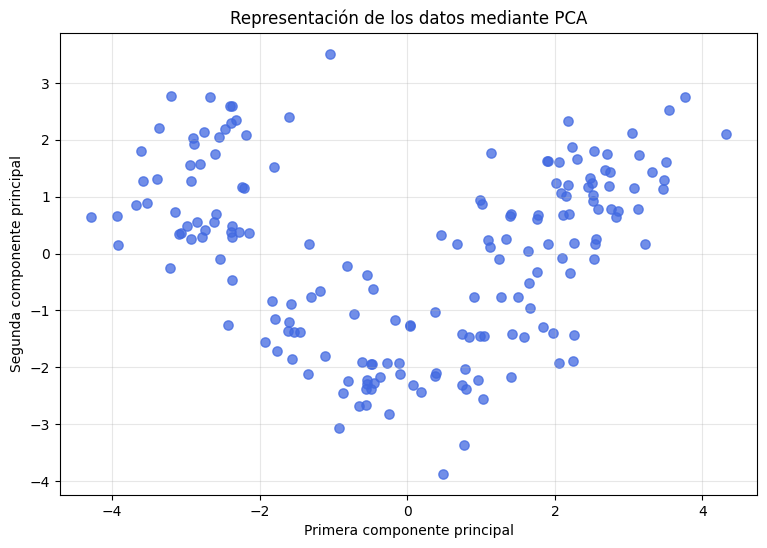

In [12]:
#VISUALIZACIÓN DE PCA


plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c="royalblue",
    s=45,
    alpha=0.75
)

plt.title("Representación de los datos mediante PCA")
plt.xlabel("Primera componente principal")
plt.ylabel("Segunda componente principal")
plt.grid(True, alpha=0.3)
plt.show()


In [13]:
#SVD: REDUCCIÓN A DOS COMPONENTES

svd = TruncatedSVD(
    n_components=2,
    random_state=42
)

X_svd = svd.fit_transform(X_escalado)

varianza_svd = svd.explained_variance_ratio_
varianza_svd_acumulada = varianza_svd.sum()

print("Dimensiones originales:", X_escalado.shape)
print("Dimensiones reducidas:", X_svd.shape)

print(
    "Varianza explicada por componente:",
    np.round(varianza_svd, 4)
)

print(
    "Varianza explicada acumulada:",
    round(varianza_svd_acumulada, 4)
)


Dimensiones originales: (178, 13)
Dimensiones reducidas: (178, 2)
Varianza explicada por componente: [0.362  0.1921]
Varianza explicada acumulada: 0.5541


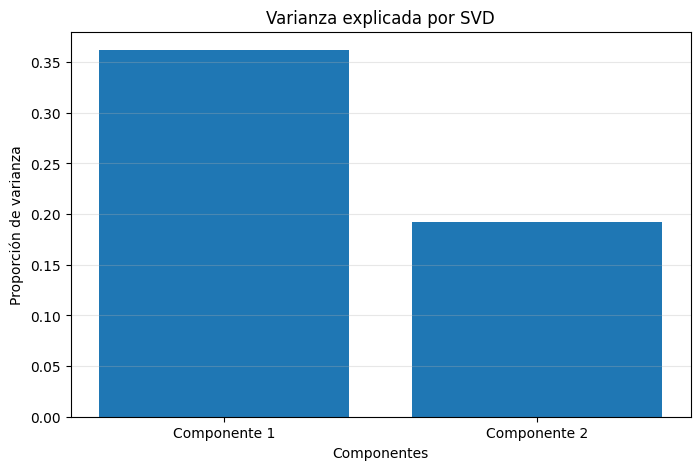

Varianza acumulada: 55.41%


In [14]:
#VARIANZA EXPLICADA POR SVD

plt.figure(figsize=(8, 5))

plt.bar(
    ["Componente 1", "Componente 2"],
    varianza_svd
)

plt.title("Varianza explicada por SVD")
plt.ylabel("Proporción de varianza")
plt.xlabel("Componentes")
plt.grid(axis="y", alpha=0.3)
plt.show()

print(
    f"Varianza acumulada: {varianza_svd_acumulada * 100:.2f}%"
)


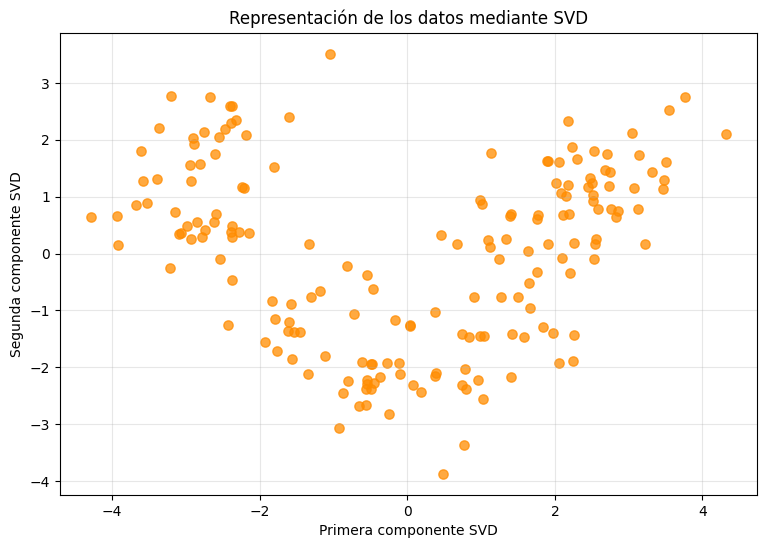

In [15]:
#VISUALIZACIÓN DE SVD

plt.figure(figsize=(9, 6))

plt.scatter(
    X_svd[:, 0],
    X_svd[:, 1],
    c="darkorange",
    s=45,
    alpha=0.75
)

plt.title("Representación de los datos mediante SVD")
plt.xlabel("Primera componente SVD")
plt.ylabel("Segunda componente SVD")
plt.grid(True, alpha=0.3)
plt.show()


In [16]:
#COMPARACIÓN DE RESULTADOS


comparacion = pd.DataFrame({
    "Método": [
        "K-means",
        "Clustering jerárquico",
        "PCA",
        "SVD"
    ],
    "Dimensiones de salida": [
        X_escalado.shape[1],
        X_escalado.shape[1],
        X_pca.shape[1],
        X_svd.shape[1]
    ],
    "Métrica": [
        "Silueta",
        "Silueta",
        "Varianza explicada acumulada",
        "Varianza explicada acumulada"
    ],
    "Resultado": [
        silueta_kmeans,
        silueta_jerarquica,
        varianza_acumulada,
        varianza_svd_acumulada
    ]
})

comparacion["Resultado"] = comparacion["Resultado"].round(4)

display(comparacion)


,Método,Dimensiones de salida,Métrica,Resultado
0,K-means,13,Silueta,0.2849
1,Clustering jerárquico,13,Silueta,0.2774
2,PCA,2,Varianza explicada acumulada,0.5541
3,SVD,2,Varianza explicada acumulada,0.5541


In [17]:
comparacion.to_csv(
    "comparacion_resultados.csv",
    index=False
)

print("Tabla exportada correctamente.")


Tabla exportada correctamente.
